# 1 - Exploración de datos

Antes de modelar reviso qué trae cada archivo, si hay errores y en qué frecuencia conviene trabajar.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src import datos

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

colores = {"X": "#6250d6", "Y": "#eda100", "Z": "#2a78d6", "Equipo1": "#1baf7a", "Equipo2": "#eb6834"}

## Carga

Los cuatro archivos vienen en formatos distintos (Y usa `;` y coma decimal, Z tiene las columnas al revés, X está en orden descendente). La lectura de cada uno está en `src/datos.py`.

`historico_equipos.csv` ya trae X, Y y Z junto con los precios de los equipos, así que trabajo con ese y uso los otros tres solo para validar.

In [2]:
df = datos.leer_equipos()
print(df.shape, df.index.min().date(), df.index.max().date())
df.head()

(3530, 5) 2010-01-04 2023-08-31


,X,Y,Z,Equipo1,Equipo2
Date,,,,,
2010-01-04,80.12,527.5,2225.25,434.73,931.73
2010-01-05,80.59,527.5,2246.50,449.97,968.56
2010-01-06,81.89,527.5,2302.50,444.48,960.51
2010-01-07,81.51,527.5,2306.50,440.90,960.14
2010-01-08,81.37,552.5,2261.25,448.82,949.55


In [3]:
datos.comparar_con_fuentes(df)

,sin_dato_en_fuente,dif_maxima
X,0.0,0.0
Y,0.0,0.0
Z,0.0,0.0


Coinciden al 100% con los archivos originales. X trae datos hasta abril 2024 (más allá del histórico de equipos), eso puede servir después.

## Calidad

In [4]:
print("nulos:", df.isna().sum().sum())
print("fechas repetidas:", df.index.duplicated().sum())
df.describe().round(1)

nulos: 0
fechas repetidas: 0


,X,Y,Z,Equipo1,Equipo2
count,3530.0,3530.0,3530.0,3530.0,3530.0
mean,78.1,555.5,2037.4,460.0,890.0
std,25.2,138.5,373.1,113.7,170.0
min,19.3,257.5,1421.5,208.3,566.0
25%,57.1,482.5,1767.2,398.2,777.7
50%,75.4,541.6,1974.8,451.2,869.8
75%,104.6,620.0,2235.9,515.6,979.1
max,128.0,1062.4,3984.0,855.3,1704.0


In [5]:
# % de días en que el precio no cambió
(df.diff() == 0).mean().mul(100).round(1)

X           0.3
Y          55.5
Z           4.1
Equipo1     0.0
Equipo2     0.1
dtype: float64

Y no cambia en más de la mitad de los días, se mueve en escalones. Las demás series cambian casi a diario.

In [6]:
# saltos de más de 8% que se revierten al día siguiente
ret = df.pct_change()
saltos = (ret.abs() > 0.08) & (ret.shift(-1).abs() > 0.08) & (np.sign(ret) != np.sign(ret.shift(-1)))

for col in df.columns:
    fechas = df.index[saltos[col]]
    if len(fechas):
        print(col, [str(f.date()) for f in fechas])

X ['2015-08-31', '2020-03-09', '2020-03-18']
Z ['2014-03-25']
Equipo2 ['2022-03-07']


- X el 31-ago-2015 (rebote fuerte del petróleo) y marzo 2020 (desplome por COVID): movimientos reales.
- Equipo2 el 7-mar-2022: coincide con el máximo de Z ese mismo día, también es real.
- **Z el 2014-03-25**: este hay que revisarlo.

## El dato de Z del 2014-03-25

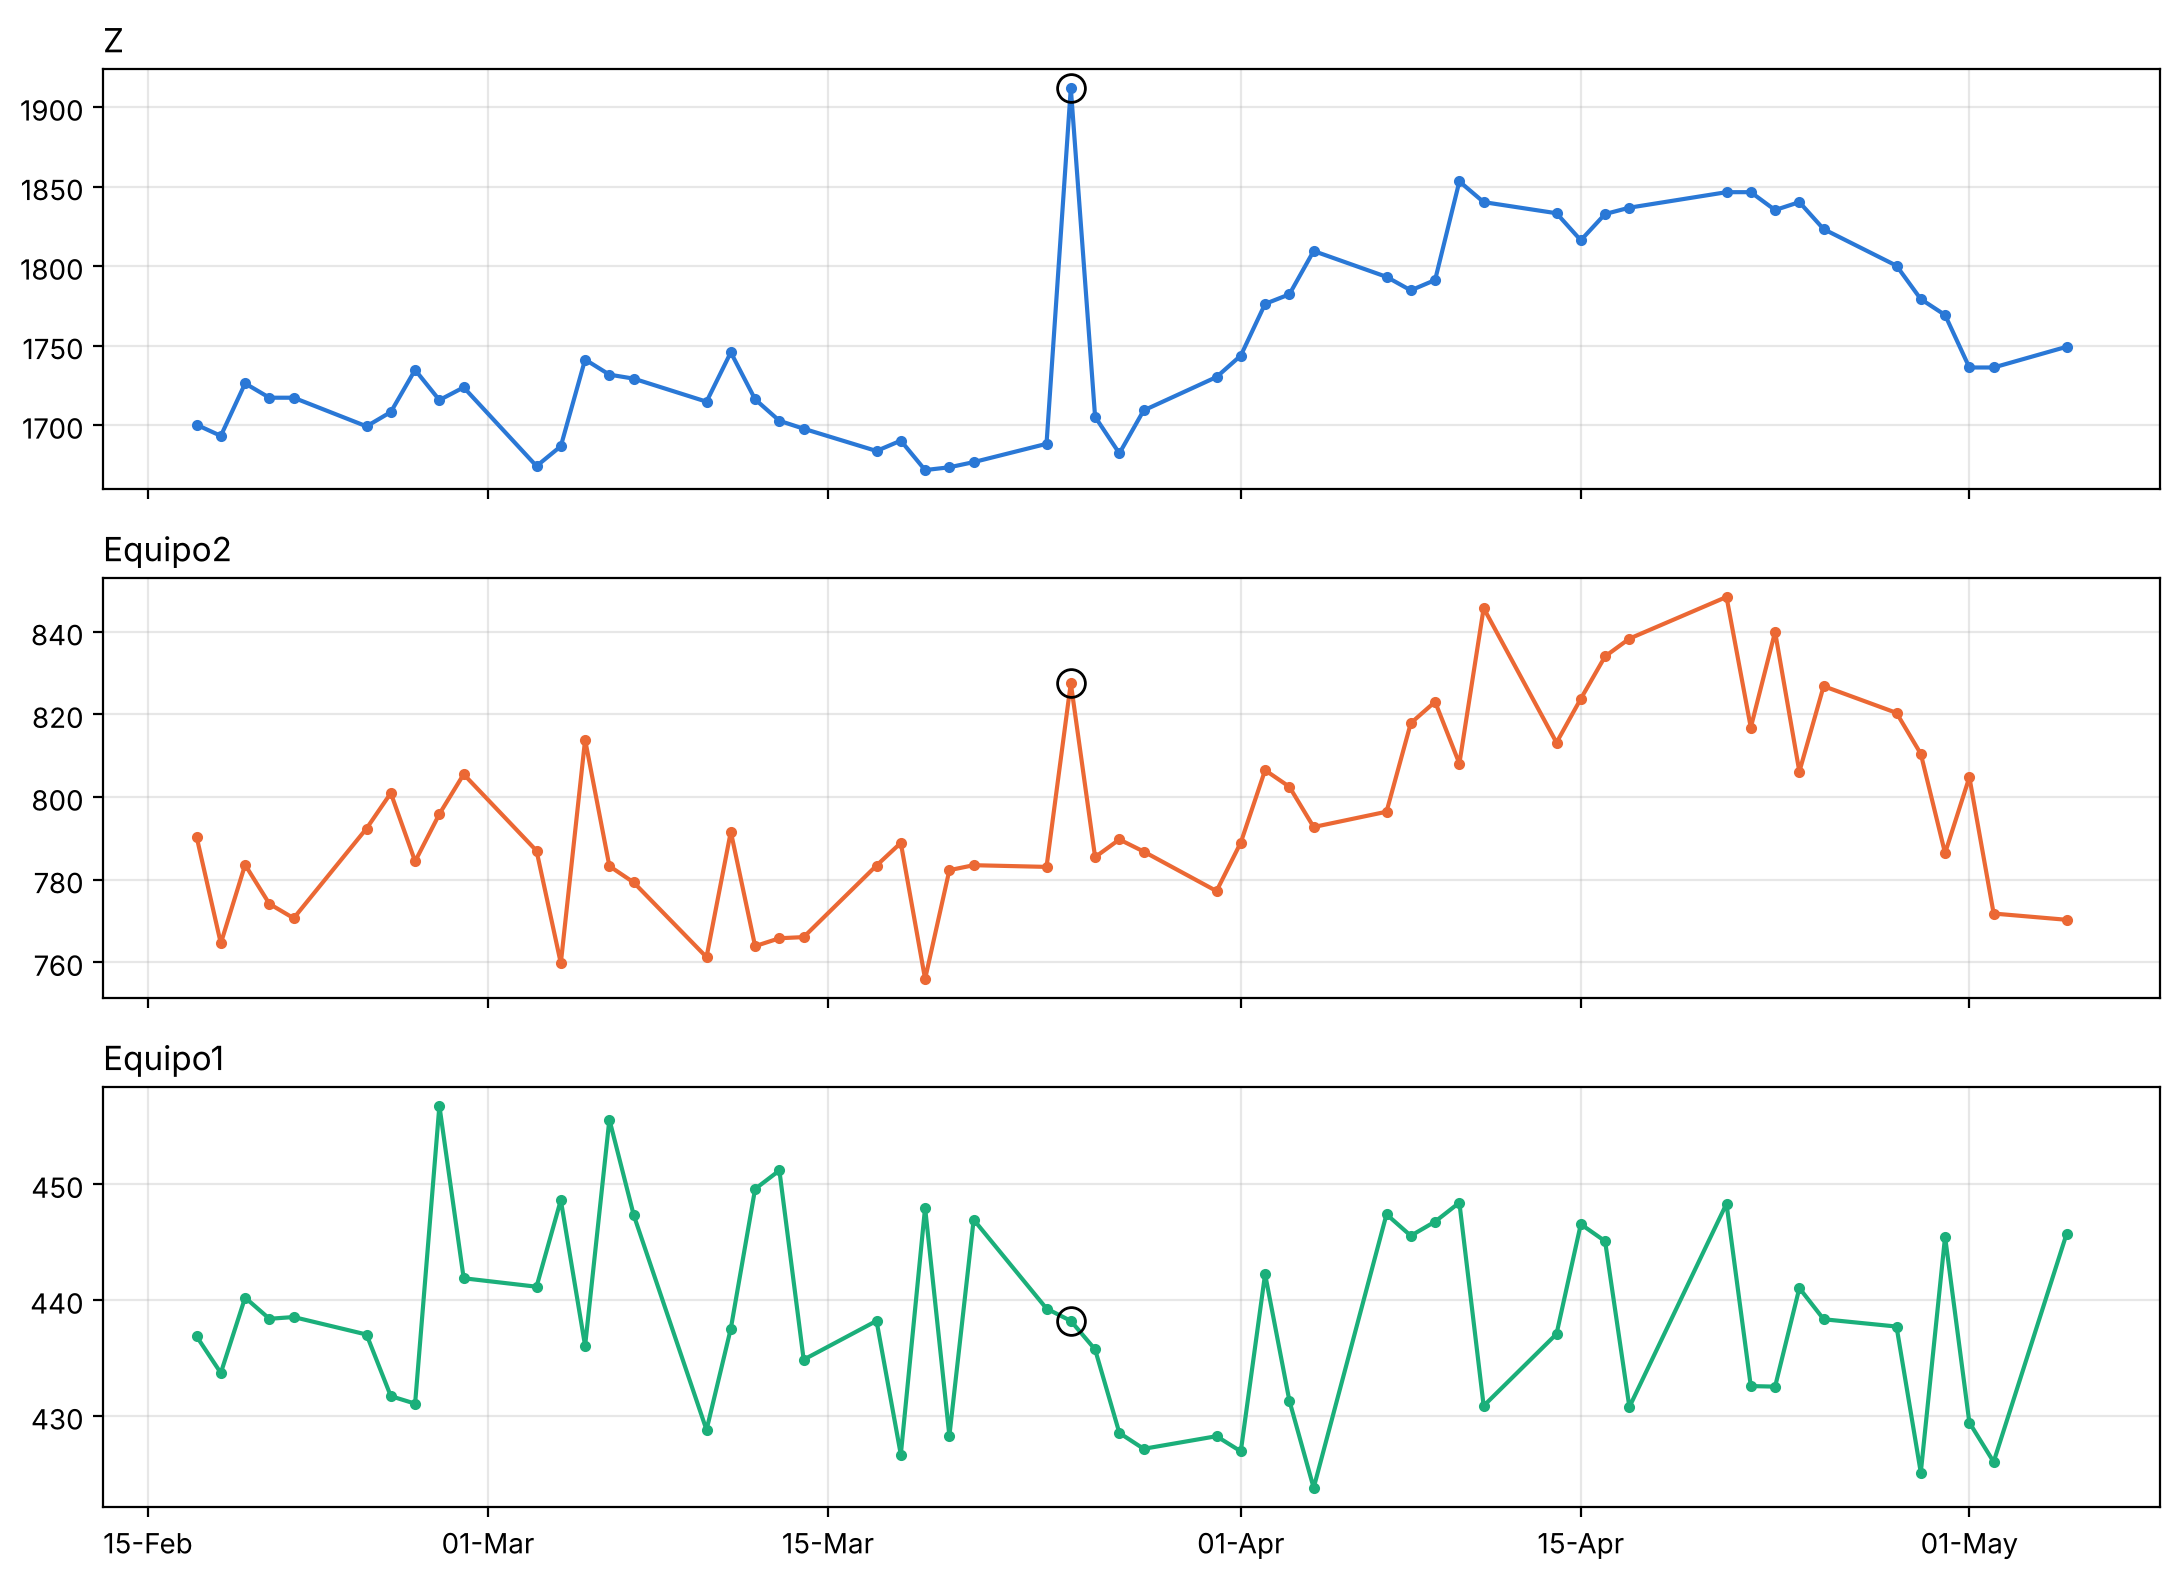

In [7]:
dia = pd.Timestamp("2014-03-25")
tramo = df.loc["2014-02-15":"2014-05-05"]

fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, col in zip(axs, ["Z", "Equipo2", "Equipo1"]):
    ax.plot(tramo[col], color=colores[col], marker="o", ms=3)
    ax.plot(dia, tramo.loc[dia, col], "o", ms=10, mfc="none", mec="k")
    ax.set_title(col, loc="left")
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
plt.tight_layout()
plt.savefig("../reports/figures/01_outlier_Z.png", dpi=120)
plt.show()

In [8]:
df.loc["2014-03-21":"2014-03-28"]

,X,Y,Z,Equipo1,Equipo2
Date,,,,,
2014-03-21,106.92,517.5,1676.750000,446.95,783.50
2014-03-24,106.81,517.5,1688.250000,439.27,783.09
2014-03-25,106.99,517.5,1911.967259,438.21,827.56
2014-03-26,107.03,517.5,1705.250000,435.74,785.46
2014-03-27,107.83,517.5,1682.250000,428.53,789.73
2014-03-28,108.07,517.5,1709.250000,427.16,786.80


Z sube de 1,688 a 1,911.97 (+13%) y al día siguiente regresa a 1,705. Además el valor tiene decimales raros, todos los demás precios de Z son múltiplos de 0.25.

Los niveles de Z cuadran con el precio cash del aluminio en la LME. Revisé las noticias de esa semana y el aluminio se movió menos de 1% ese día (SMM Aluminum Market Morning Review, 26-mar-2014), así que no fue un evento de mercado: es un error en el dato.

Lo interesante es que **Equipo2 también sube ese día (+6%) y Equipo1 no**. Parece que el precio de Equipo2 se calcula con el Z del mismo día. Lo pruebo en el notebook 02.

Decisión: quito ese día completo en lugar de interpolar Z, para no modificar el precio del equipo ni inventar valores.

## Frecuencia

El caso pide proyectar costos de los próximos meses, así que armo una versión semanal y otra mensual (promedio del periodo) y las comparo en el siguiente notebook.

In [9]:
df_limpio = datos.quitar_outliers(df)
semanal = datos.agregar(df_limpio, "W-FRI")
mensual = datos.agregar(df_limpio, "MS")

semanal.to_csv(datos.PROCESSED / "equipos_semanal.csv")
mensual.to_csv(datos.PROCESSED / "equipos_mensual.csv")

len(df_limpio), len(semanal), len(mensual)

(3529, 713, 164)

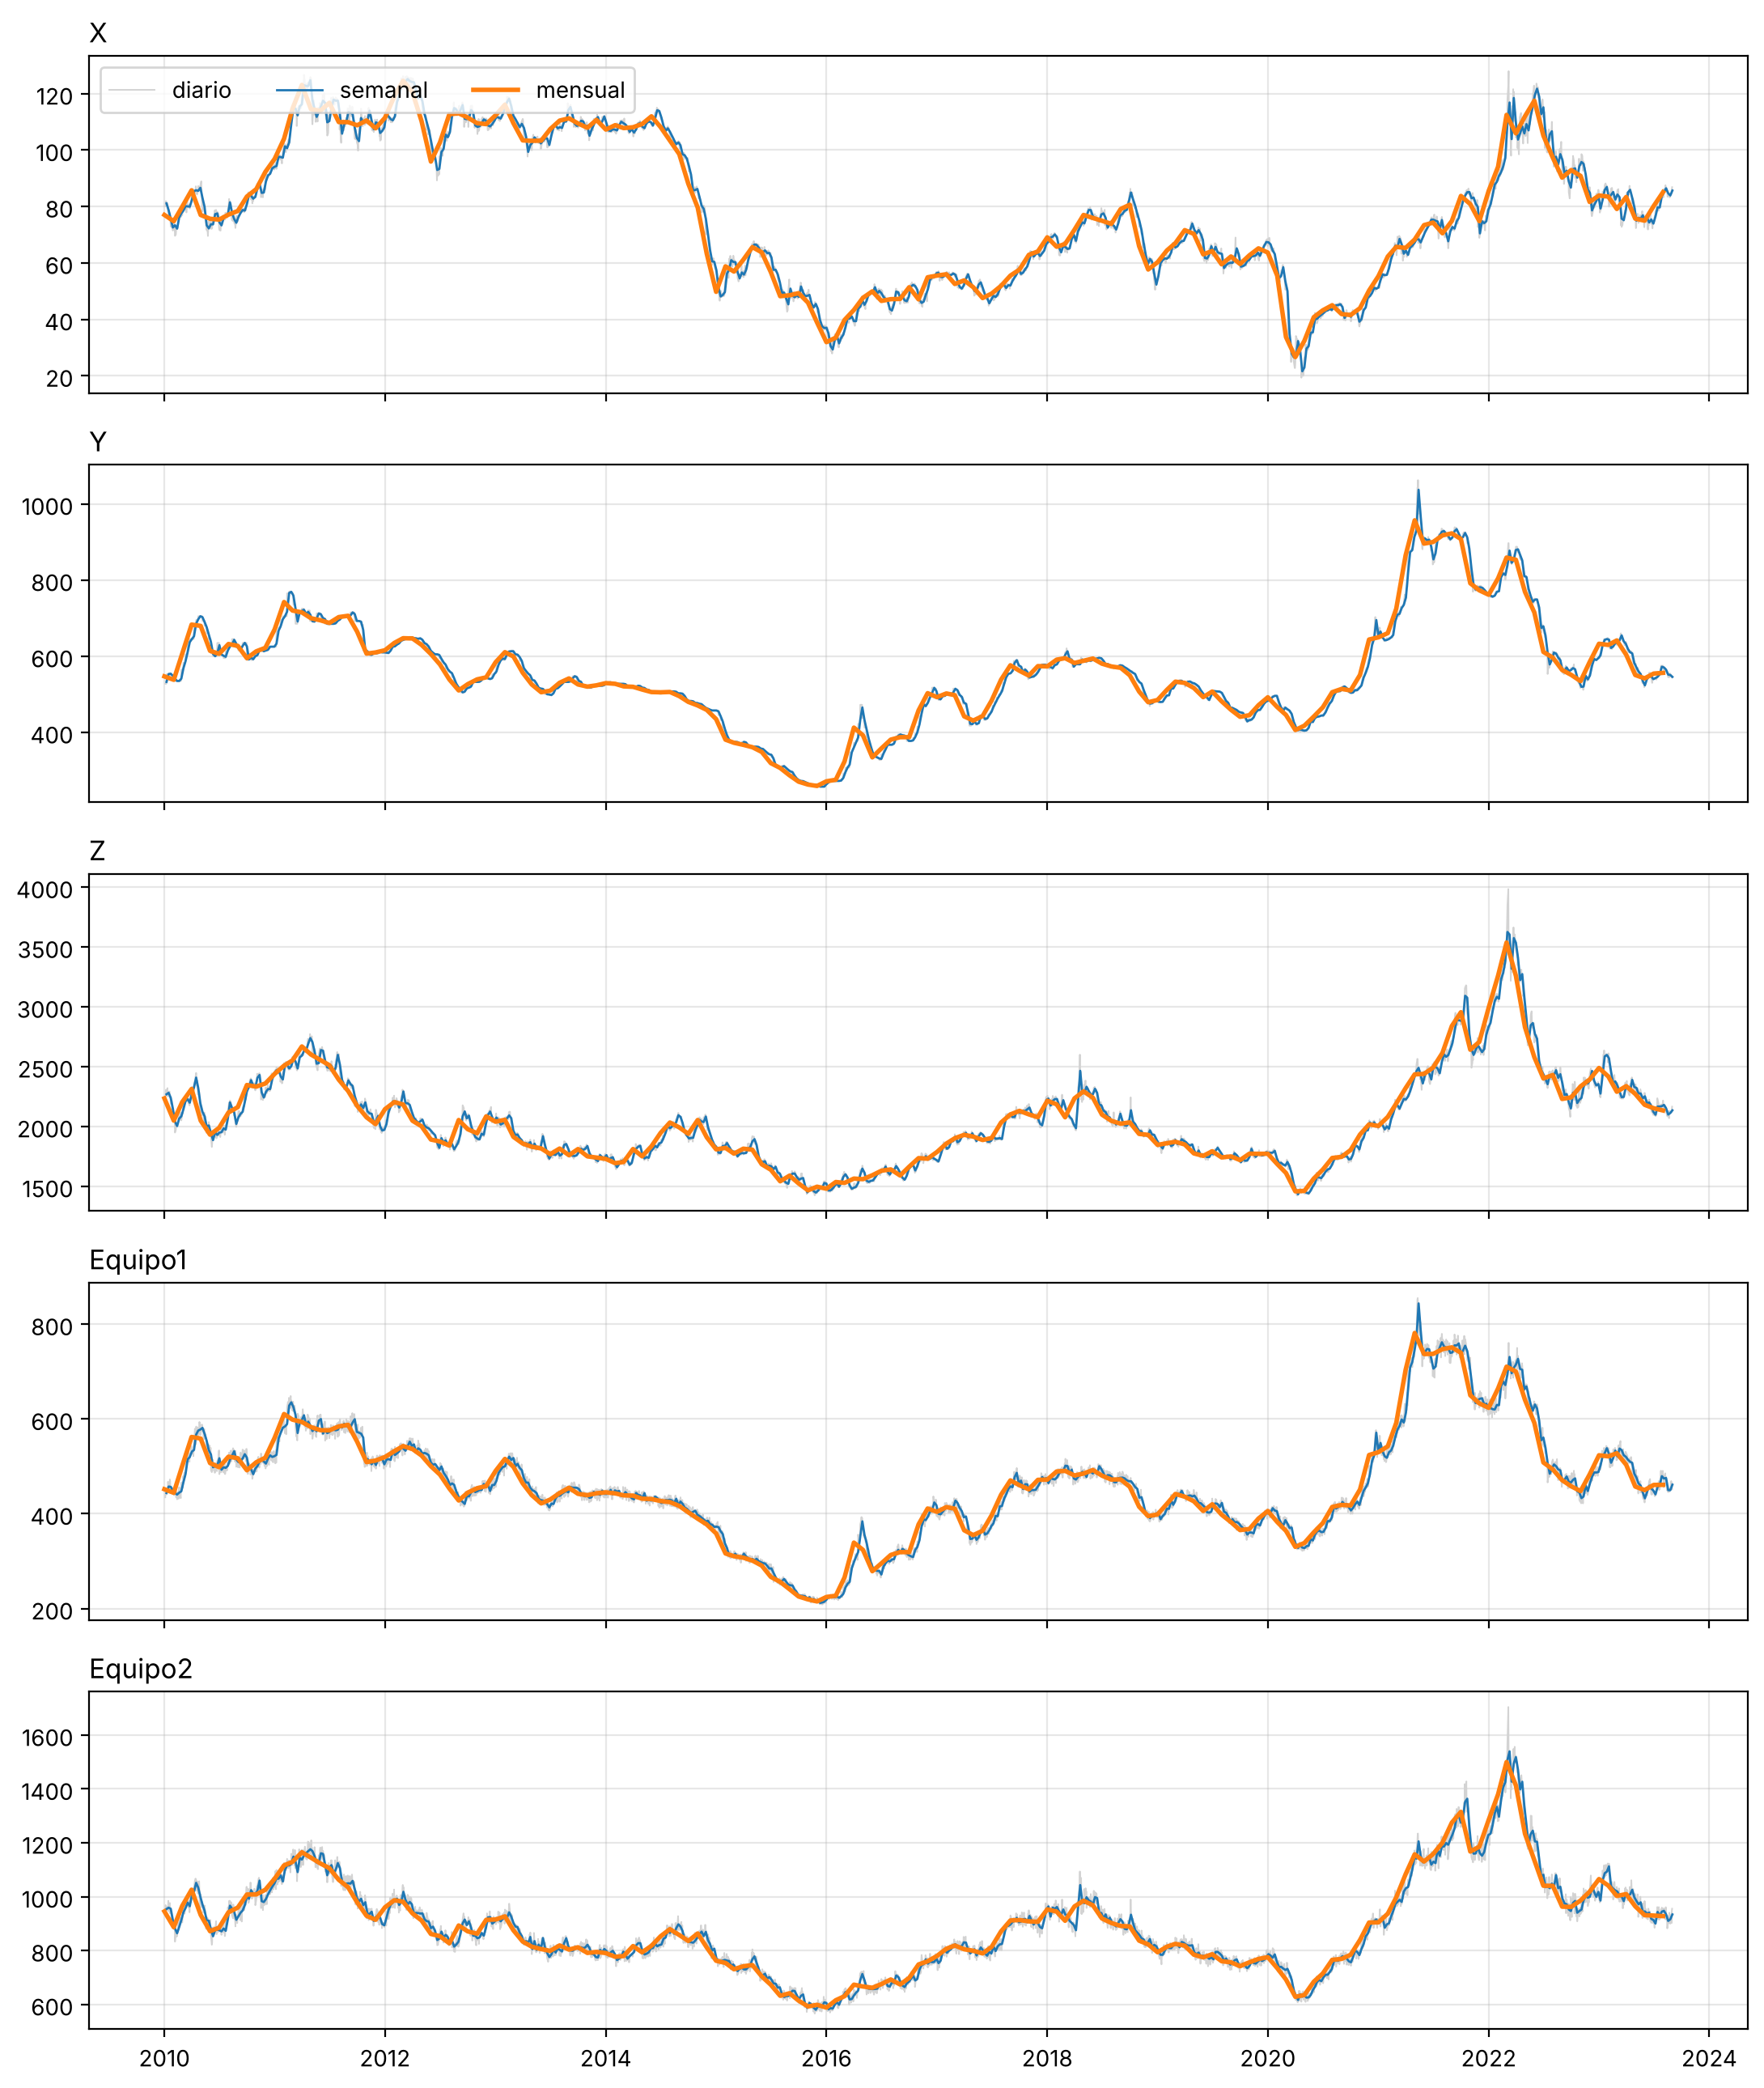

In [10]:
fig, axs = plt.subplots(5, 1, figsize=(11, 13), sharex=True)
for ax, col in zip(axs, df.columns):
    ax.plot(df_limpio[col], color="lightgray", lw=0.7, label="diario")
    ax.plot(semanal[col], lw=1, label="semanal")
    ax.plot(mensual[col], lw=2, label="mensual")
    ax.set_title(col, loc="left")
axs[0].legend(ncol=3, loc="upper left")
plt.tight_layout()
plt.savefig("../reports/figures/01_frecuencias.png", dpi=120)
plt.show()

## Resumen

- Los datos son consistentes entre archivos. Un solo error: Z el 2014-03-25, se excluye.
- Visualmente Equipo1 se parece mucho a Y, y Equipo2 a Z. X tiene otro comportamiento (por ejemplo, su caída de 2014-2015 no aparece igual en los equipos).
- Siguiente: probar estas relaciones con estadística (notebook 02).